      device  conversion
0     Mobile           0
1     Mobile           1
2     Mobile           0
3     Mobile           1
4     Mobile           1
..       ...         ...
195  Desktop           1
196  Desktop           0
197  Desktop           0
198  Desktop           1
199  Desktop           1

[200 rows x 2 columns]
device
Desktop    0.30
Mobile     0.49
Name: conversion, dtype: float64


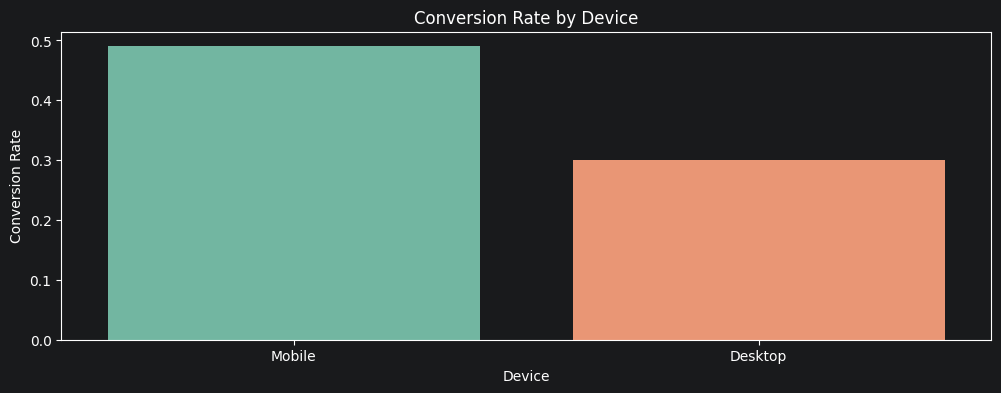

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df_hyp = pd.DataFrame({
    'device':['Mobile']* 100 + ['Desktop']*100,
    'conversion' : np.concatenate([np.random.binomial(1, 0.5, 100), np.random.binomial(1, 0.3, 100)])
})

print(df_hyp)

conversion_rate_by_device = df_hyp.groupby('device')['conversion'].mean()
print(conversion_rate_by_device)

plt.figure(figsize=(12,4))
sns.barplot(x='device', y='conversion', hue='device',  data=df_hyp, errorbar=None, palette='Set2', legend=False)
plt.title('Conversion Rate by Device')
plt.xlabel('Device')
plt.ylabel('Conversion Rate')
plt.show()


In [13]:
np.random.seed(42)
control_group = np.random.normal(125.0 , 8.0 , 25)
print("Control Group:\n", control_group)

camp_group = np.random.normal(135.0 , 8.0 , 25)
print("Campaign Group:\n", camp_group)

t_stats, p_value = stats.ttest_ind(camp_group, control_group, alternative='greater')
print(f"Average Strike Rate - Control Group: {np.mean(control_group):.2f}")
print(f"Average Strike Rate - Campaign Group: {np.mean(camp_group):.2f}")
print('-'*60)
print(f"T-statistics : {t_stats:.2f}")
print(f"P-value : {p_value:.2f}")
print('-' * 60)

if p_value < 0.05:
    print("Reject the null hypothesis: The campaign group has a significantly higher strike rate than the control group.")
else:
    print("Fail to reject the null hypothesis: No significant difference in strike rates between the two groups.")

Control Group:
 [128.97371322 123.89388559 130.1815083  137.18423885 123.126773
 123.12690434 137.63370252 131.13947783 121.24420491 129.34048035
 121.29265846 121.27416197 126.93569817 109.69375804 111.20065734
 120.50169977 116.89735104 127.51397866 117.7358074  113.70157039
 136.72519015 123.1937896  125.54022564 113.60201451 120.6449382 ]
Campaign Group:
 [135.88738072 125.79205138 138.00558415 130.19489048 132.66645
 130.1863471  149.81822548 134.8920222  126.53831257 141.5803593
 125.2332508  136.67090876 119.32263901 124.37451161 136.57488989
 140.90773264 136.37094625 134.07481374 132.59117044 123.17182408
 129.24124633 131.31488983 143.45697781 137.74894632 120.89567876]
Average Strike Rate - Control Group: 123.69
Average Strike Rate - Campaign Group: 132.70
------------------------------------------------------------
T-statistics : 4.23
P-value : 0.00
------------------------------------------------------------
Reject the null hypothesis: The campaign group has a significantl

# 2. Segnent Based Deep Dives ( Slicing and Dicing )
- Segment - based deep dives involve slicing and dicing the data based on specific segments or categories to uncover insights that may not be apparent in the overall dataset. This approach allows for a more granular analysis of how different segments behave, which can inform targeted strategies and decision-making.
- formula - $$M_K = E[Y|Segment = S_K], \sum_k P(S_K)M_K = M$$
- S_K : "Segment sub-pouplation cohort K"

In [21]:
data = [
    {"Batter": 'Batter A', 'Pitch': 'Flat', 'Innings': 90, 'Runs': 4500},
    {"Batter": 'Batter A', 'Pitch': 'Swinging', 'Innings': 90, 'Runs': 4800},
    {"Batter": 'Batter B', 'Pitch': 'Flat', 'Innings': 85, 'Runs': 4000},
    {"Batter": 'Batter B', 'Pitch': 'Swinging', 'Innings': 85, 'Runs': 4200},
    {"Batter": 'Batter C', 'Pitch': 'Flat', 'Innings': 80, 'Runs': 3500},
    {"Batter": 'Batter C', 'Pitch': 'Swinging', 'Innings': 80, 'Runs': 3700}

]

df = pd.DataFrame(data)
print(df)

df['Average']= df['Runs']/ df['Innings']
print('_' * 60)
print(df)
print("_"* 60)
print("Break Down by Pitch type ")
print(df[['Batter', 'Pitch', 'Innings', 'Average']])
print('_'* 60)
print(df.pivot(index='Batter', columns='Pitch', values='Average'))
print('_'* 60)
overall = df.groupby('Batter').agg({'Innings':'sum', 'Runs':'sum'}).reset_index()
print(overall)
print('_'* 60)
overall['Overall_Average'] = overall['Runs'] / overall['Innings']
print(overall[['Batter', 'Innings', 'Runs', 'Overall_Average']])

     Batter     Pitch  Innings  Runs
0  Batter A      Flat       90  4500
1  Batter A  Swinging       90  4800
2  Batter B      Flat       85  4000
3  Batter B  Swinging       85  4200
4  Batter C      Flat       80  3500
5  Batter C  Swinging       80  3700
____________________________________________________________
     Batter     Pitch  Innings  Runs    Average
0  Batter A      Flat       90  4500  50.000000
1  Batter A  Swinging       90  4800  53.333333
2  Batter B      Flat       85  4000  47.058824
3  Batter B  Swinging       85  4200  49.411765
4  Batter C      Flat       80  3500  43.750000
5  Batter C  Swinging       80  3700  46.250000
____________________________________________________________
Break Down by Pitch type 
     Batter     Pitch  Innings    Average
0  Batter A      Flat       90  50.000000
1  Batter A  Swinging       90  53.333333
2  Batter B      Flat       85  47.058824
3  Batter B  Swinging       85  49.411765
4  Batter C      Flat       80  43.750000
5  Ba

In [ ]:
np.random.seed(42)
n=100
x_simpson = np.concatenate([np.linespace(1, 5, 50), np.linspace(6, 10, 50)])
y_simpson = np.concatenate([np.random.normal(10, 2, 50),)

